# Neural integration for constitutive equations 

### Benchmark #1: elasto-plastic material

Authors: Filippo Masi, Itai Einav

### 1. Import libraries

In [1]:
import pickle
import numpy as np
import torch
from scipy.optimize import root
from torchdiffeq import odeint
from nice_module import NICE_reduced, EarlyStopping, slice_data, get_params

np.random.seed(6)
torch.manual_seed(6)

# plotting
import matplotlib.pyplot as plt
import matplotlib
plt.style.use('classic')
plt.rcParams.update({"axes.grid" : False, "grid.color": 'black', "grid.alpha":0.4})
font = {'size'   : 11}
matplotlib.rc('font', **font)
plt.rcParams['axes.facecolor']='none'
plt.rcParams['savefig.facecolor']='none'
plt.rcParams['figure.facecolor']='none'
plt.rcParams["figure.figsize"] = (2.5,2)
plt.tight_layout(pad=2.5, w_pad=3.5, h_pad=3.5)
colorb = (0.2,0.4,0.7)

<Figure size 200x160 with 0 Axes>

#### 1.1 Set hyperparameters

In [2]:
# Setting the frequency in epochs for printing loss during training
verbose_frequency = 10

# Step size for the training process. If set to 20, it reproduces the original results
# otherwise, set to 1 for faster training.
step_size = 20

# Checking for GPU availability and assigning the device accordingly
device = torch.device('cuda:' + str(gpu) if torch.cuda.is_available() else 'cpu')

# Boolean flag for adding normally distributed noise to the training dataset
corrupted_training_data = False

# If corrupted_training_data is True, set the noise amplitude (percentage)
delta = 0.  # Noise amplitude (percentage) if corrupted_training_data is True

### 2. Import and prepare data sets

In [3]:
# File path for the training dataset
file = './dataset/benchmark1_data_training'

# Loading data from the specified file using pickle
with open(file, 'rb') as f_obj:
    data = pickle.load(f_obj)

# Unpacking data into individual variables
[strain_t,strain_tdt,stress_t,dt,n_reset] = data

# Setting batch_time equal to n_reset
batch_time = n_reset

# Setting data_size equal to n_reset
data_size = n_reset

# Dimensionality of the data
dim = 2

# Setting prm_dt as the reciprocal of data_size
prm_dt = 1 / data_size

#### 3.1 Reshape 


In [4]:
dstrain = strain_tdt - strain_t
dstrain/=prm_dt

strain_t = np.reshape(strain_t,(batch_time,-1,dim),order='F')
strain_tdt = np.reshape(strain_tdt,(batch_time,-1,dim),order='F')
dstrain = np.reshape(dstrain,(batch_time,-1,dim),order='F')

stress_t = np.reshape(stress_t,(batch_time,-1,dim),order='F')

data_size = strain_t.shape[0]
number_IC = strain_t.shape[1]

#### 3.2 Split data in training, validation, and test sets 

In [5]:
# Percentage of data to be used for training
train_percentage = 0.65

# Calculating the number of samples for training, validation, and testing
train = int(round(number_IC * train_percentage))
val = int(round(number_IC * 0.5 * (1. - train_percentage)))
test = val

# Printing information about the data split
print("Number of samples: ", number_IC)
print("Training samples: ", train)
print("Validation samples: ", val)
print("Test samples: ", test)
print("Total: ", test + val + train)

Number of samples:  24
Training samples:  16
Validation samples:  4
Test samples:  4
Total:  24


In [6]:
# Creating an array of sequential numbers from 0 to number_IC - 1
n = np.arange(0, number_IC, 1)

# Creating an array of indices and shuffling it
rnd = np.arange(len(n))
np.random.shuffle(rnd)
n = n[rnd]

# Splitting the shuffled indices into training, validation, and test sets
ntrain = n[:train]
cut = len(ntrain)
nval = n[train:]
ntrainval = np.hstack((ntrain, nval))
ntest = n[train + val:]

# Shuffling the indices for training and validation combined set
rnd = np.arange(len(ntrainval))
np.random.shuffle(rnd)

# Splitting the shuffled indices for training and validation sets
ntrain = rnd[:train]
nval = rnd[val:]

In [7]:
# Slicing the strain data into training-validation and test sets
strain_t_tv, strain_t_test = slice_data(strain_t, ntrainval, ntest)

# Slicing the time derivative of strain data into training-validation and test sets
strain_tdt_tv, strain_tdt_test = slice_data(strain_tdt, ntrainval, ntest)

# Slicing the incremental strain data into training-validation and test sets
dstrain_tv, dstrain_test = slice_data(dstrain, ntrainval, ntest)

# Slicing the stress data into training-validation and test sets
stress_t_tv, stress_t_test = slice_data(stress_t, ntrainval, ntest)

In [8]:
# Checking if training data needs to be corrupted with noise
if corrupted_training_data:

    # Generating a stress noise vector
    noise = delta/100 * np.random.normal(0, 1, ((data_size+1, number_IC, dim)))
    
    # Copying the stress data to apply noise
    noise_stress_t = stress_t_tv.copy()
    
    # Adding noise to the stress data
    noise_stress_t[:, :, 0] = np.mean(stress_t_tv[:, :, 0]) * noise[:-1, :, 0]
    noise_stress_t[:, :, 1] = np.mean(stress_t_tv[:, :, 1]) * noise[:-1, :, 1]
    
    # Setting the initial time step to zero
    noise_stress_t[0] *= 0.0
    
    # Adding the noise to the original stress data
    stress_t_tv += noise_stress_t

In [9]:
prm_e = get_params(strain_t_tv).to(device)
prm_de = get_params(dstrain_tv).to(device)
prm_s = get_params(stress_t_tv).to(device)

### 4. Neural integration for constitutive equations

#### 4.1 Constructu neural net and set integration scheme

In [10]:
dtype=torch.float64
NNf_params = [2*dim,dim,[6*(2*dim),6*(2*dim),6*(2*dim),],'gelu']
NNu_params = [2,1,[2**6,2**6],'softplus']
norm_params = [prm_e,prm_de,prm_s,prm_dt]
nsvars = 1
number_IC = len(ntrainval)
NICE_network = NICE_reduced(NNf_params,NNu_params,number_IC,norm_params,dim,dtype).to(device)
NICE_network.to(torch.double)

NICE_reduced(
  (NeuralNetEvolution): Sequential(
    (0): Linear(in_features=4, out_features=24, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=24, out_features=24, bias=True)
    (3): GELU(approximate='none')
    (4): Linear(in_features=24, out_features=24, bias=True)
    (5): GELU(approximate='none')
    (6): Linear(in_features=24, out_features=2, bias=True)
  )
  (NeuralNetEnergy): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Softplus(beta=1, threshold=20)
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Softplus(beta=1, threshold=20)
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
  (relu): ReLU()
)

In [11]:
# Calculating the time step for the simulation
prm_dt = 1 / data_size

# Creating a time array from 0 to 1 with the calculated time step
t = torch.arange(0, 1.0, prm_dt)

# Converting stress and incremental strain data to torch tensors and moving them to the specified device
stress_tv = torch.from_numpy(np.float64(stress_t_tv)).to(device)
dstrain_tv = torch.from_numpy(np.float64(dstrain_tv)).to(device)

# Converting test set stress and incremental strain data to torch tensors and moving them to the specified device
stress_test = torch.from_numpy(np.float64(stress_t_test)).to(device)
dstrain_test = torch.from_numpy(np.float64(dstrain_test)).to(device)

In [12]:
# Setting the solver type for the NICE network
NICE_network.solver = "midpoint"

# Setting the integration scheme for the NICE network
NICE_network.scheme = "forward"

# Setting the step size for the integration in the NICE network
NICE_network.step_size = prm_dt / step_size

# Initializing the interpolation function for incremental strain and time in the NICE network
NICE_network.init_interp(dstrain_tv, t)

# Turning off the inference mode in the NICE network
NICE_network.inference = False

#### 4.2 Training

In [13]:
# Setting the learning rate for the optimizer
learningRate = 1e-2

# Initializing the Adam optimizer with the NICE network parameters
optimizer = torch.optim.Adam(NICE_network.parameters(), lr=learningRate)

# Setting up a learning rate scheduler to adjust the learning rate during training
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.999)

# L2 penalty weight for regularization
w_reg = 1.e-5

# Number of training epochs
Nepochs = 1000000

# Mean Squared Error (MSE) loss function
MSE = torch.nn.MSELoss()

# Setting up early stopping with specified criteria
checkpoint_path = '/home/user/nice/reproduction/output/pretrained/checkpoint.pt'
early_stopping = EarlyStopping(patience=2000, delta=1.e-9, verbose=False, path=checkpoint_path)

# Lists for storing training and validation loss history
training_loss_hist = []
validation_loss_value_hist = []

In [14]:
NICE_network.load_state_dict(torch.load('./saved/[state]NICE_benchmark1'))
print('loaded authors weights')

loaded authors weights


#### 4.3 Training and validation set evaluation

In [15]:
# Define time array for evaluation
t = prm_dt * torch.linspace(0., data_size - 1, data_size).to(device)

# Get the number of initial conditions
number_IC = stress_tv.shape[1]

# Find initial elastic strain using root finding
initial_elastic_strain = root(NICE_network.find_elastic_strain,
                              args=(stress_tv[0].reshape(-1, 2)),
                              x0=np.zeros((24, 2)),
                              tol=1e-12)

# Convert the result to a torch tensor
eps_e_0 = torch.from_numpy(initial_elastic_strain.x.reshape(-1, 2))

# De-normalize the initial elastic strain
ueps_e_0 = NICE_network.DeNormalize(eps_e_0, NICE_network.prm_ee)

# Inference mode: make predictions
pred_svars, pred_stress, pred_diss = NICE_network.integrate(dstrain_tv, ueps_e_0, t, np.hstack((ntrain, nval)))

# Evaluate the Mean Absolute Error (MAE) for stress
loss = torch.nn.L1Loss()
MAE_stress = loss(NICE_network.Normalize(pred_stress, prm_s), NICE_network.Normalize(stress_tv[:, :, :dim], prm_s))

# Print the MAE for stress
print("MAE stress: ", MAE_stress)

MAE stress:  tensor(0.0058, dtype=torch.float64, grad_fn=<MeanBackward0>)


#### 4.4 Test set evaluation

In [16]:
# Get the number of initial conditions for the test set
number_IC = stress_test.shape[1]

# Define time array for evaluation
t = prm_dt * torch.linspace(0., data_size - 1, data_size).to(device)

# Initialize interpolation for the test set
NICE_network.init_interp(dstrain_test, t)

# Find initial elastic strain using root finding
initial_elastic_strain = root(NICE_network.find_elastic_strain,
                              args=(stress_test[0].reshape(-1, 2)),
                              x0=np.zeros((number_IC, 2)),
                              tol=1e-12)

# Convert the result to a torch tensor
eps_e_0 = torch.from_numpy(initial_elastic_strain.x.reshape(-1, 2))

# De-normalize the initial elastic strain
ueps_e_0 = NICE_network.DeNormalize(eps_e_0, NICE_network.prm_ee)

# Create an array for the number of initial conditions in the test set
Ntest = np.arange(0, dstrain_test.shape[1])

# Inference mode: make predictions
NICE_network.inference = True
pred_svars, pred_stress, pred_diss = NICE_network.integrate(dstrain_test, ueps_e_0, t, Ntest)

# Evaluate the Mean Absolute Error (MAE) for stress
MAE_stress = loss(NICE_network.Normalize(pred_stress, prm_s), NICE_network.Normalize(stress_test[:, :, :dim], prm_s))

# Print the MAE for stress
print("MAE stress: ", MAE_stress)

MAE stress:  tensor(0.0048, dtype=torch.float64, grad_fn=<MeanBackward0>)


### 5. Inference

In [17]:
# File path for the inference dataset
file = './dataset/benchmark1_data_inference_DrainedTriaxial'
# file = '../CModel/reference_data/DP_DT_rec6'#DP_CyDTp_recall'

# Loading data from the specified file using pickle
with open(file, 'rb') as f_obj:
    data = pickle.load(f_obj)

# Unpacking data into individual variables
[stress_t, strain_t, svars_e_t, svars_p_t,
 stress_tdt, strain_tdt, svars_e_tdt, svars_p_tdt, _, _, dt, n_reset] = data

# Setting batch_time and data_size based on the values from the inference dataset
batch_time = n_reset
data_size = n_reset

In [18]:
# Computing the incremental stress, strain, and elastic state variables
dstress = stress_tdt - stress_t
dstrain = strain_tdt - strain_t
dsvars_e = svars_e_tdt - svars_e_t

# Scaling the incremental stress, strain, and elastic state variables by the time step
dstress /= prm_dt
dstrain /= prm_dt
dsvars_e /= prm_dt

In [19]:
# Reshaping strain, incremental strain, elastic strain, and stress data arrays for better organization
strain_t = np.reshape(strain_t, (batch_time, -1, dim), order='F')
dstrain = np.reshape(dstrain, (batch_time, -1, dim), order='F')
el_strain_t = np.reshape(svars_e_t, (batch_time, -1, dim), order='F')
stress_t = np.reshape(stress_t, (batch_time, -1, dim), order='F')

# Updating data_size based on the reshaped strain_t array
data_size = strain_t.shape[0]

# Calculating the number of initial conditions
number_IC = strain_t.shape[1]

In [20]:
# Set NICE network to inference mode
NICE_network.inference = True

# Create a time array for inference
t = torch.arange(0, prm_dt * data_size, prm_dt)

# Concatenate stress and elastic strain for input data
y = torch.cat((torch.from_numpy(np.float64(stress_t)), torch.from_numpy(np.float64(el_strain_t))), -1).to(device)

# Convert incremental strain and stress to torch tensors and move to the specified device
arg = torch.from_numpy(np.float64(dstrain)).to(device)
sigma = torch.from_numpy(np.float64(stress_t)).to(device)

In [21]:
# Initialize interpolation for incremental strain and time
NICE_network.init_interp(arg, t)

# Create an array of indices
idx = np.arange(0, arg.shape[1])

# Find initial elastic strain using root finding
sol = root(NICE_network.find_elastic_strain, args=(sigma[0].reshape(-1, 2)),
           x0=np.zeros((number_IC, dim)),
           tol=1e-12)

# Convert the result to a torch tensor
eps_e_0 = torch.from_numpy(sol.x.reshape(-1, 2))

# De-normalize the initial elastic strain
ueps_e_0 = NICE_network.DeNormalize(eps_e_0, NICE_network.prm_ee)

# Inference mode: make predictions
pred_svars, pred_stress, pred_diss = NICE_network.integrate(arg[:], ueps_e_0, t[:], idx)

# Convert predictions to NumPy arrays
pred_svars = pred_svars.cpu().detach().numpy()
pred_stress = pred_stress.cpu().detach().numpy()
pred_diss = pred_diss.cpu().detach().numpy()

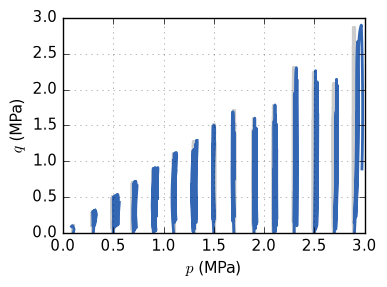

In [22]:
# Create a figure for the plot
fig = plt.figure(dpi=100, figsize=(4, 3.), tight_layout=True)

# Create a subplot
ax = fig.subplots(1)

# Plot reference stress points
for i in np.arange(sigma.shape[1]):
    ax.plot(y[:, i, 0].cpu().detach() / 1e+3, y[:, i, 1].cpu().detach() / 1e+3,
            marker='o', markerfacecolor='white', linestyle='-',
            color='black', alpha=0.2, linewidth=3, markersize=0, label='ref')

# Plot predicted stress points
for i in np.arange(pred_stress.shape[1]):
    ax.plot(pred_stress[:, i, 0] / 1e+3, pred_stress[:, i, 1] / 1e+3, alpha=1, linewidth=2, color=colorb,
            markersize=0, markeredgewidth=0.0, marker='.')

# Set labels and grid
ax.set_ylabel('$q$ (MPa)')
ax.set_xlabel('$p$ (MPa)')
ax.grid()
plt.show()

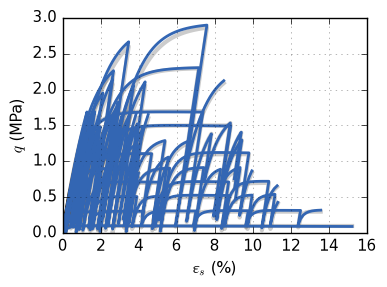

In [23]:
# Create a figure for the plot
fig = plt.figure(dpi=100, figsize=(4, 3.), tight_layout=True)

# Create a subplot
ax = fig.subplots(1)

# Plot reference stress points against strain
for i in np.arange(sigma.shape[1]):
    ax.plot(strain_t[:, i, 1] * 1e+5, y[:, i, 1].cpu().detach() / 1e+3,
            marker='o', markerfacecolor='white', linestyle='-',
            color='black', alpha=0.2, linewidth=3, markersize=0, label='ref')

# Plot predicted stress points against strain
for i in np.arange(pred_stress.shape[1]):
    ax.plot(strain_t[:, i, 1] * 1e+5, pred_stress[:, i, 1] / 1e+3, alpha=1, linewidth=2, color=colorb,
            markersize=0, markeredgewidth=0.0, marker='.')

# Set labels and grid
ax.set_ylabel('$q$ (MPa)')
ax.set_xlabel('$\\varepsilon_s$ (%)')
ax.grid()
plt.show()

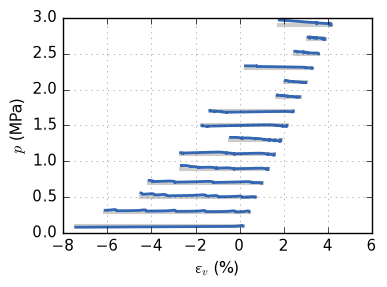

In [24]:
# Create a figure for the plot
fig = plt.figure(dpi=100, figsize=(4, 3.), tight_layout=True)

# Create a subplot
ax = fig.subplots(1)

# Plot reference stress points against volumetric strain
for i in np.arange(sigma.shape[1]):
    ax.plot(strain_t[:, i, 0] * 1e+5, y[:, i, 0].cpu().detach() / 1e+3,
            marker='o', markerfacecolor='white', linestyle='-',
            color='black', alpha=0.2, linewidth=3, markersize=0, label='ref')

# Plot predicted stress points against volumetric strain
for i in np.arange(pred_stress.shape[1]):
    ax.plot(strain_t[:, i, 0] * 1e+5, pred_stress[:, i, 0] / 1e+3, alpha=1, linewidth=2, color=colorb,
            markersize=0, markeredgewidth=0.0, marker='.')

# Set labels and grid
ax.set_ylabel('$p$ (MPa)')
ax.set_xlabel('$\\varepsilon_v$ (%)')
ax.grid()
plt.show()

### 6. Save model

In [25]:
# Define the path for saving the NICE network state dictionary
PATH = '/home/user/nice/reproduction/output/pretrained/state_NICE_benchmark1.pt'

# Save the state dictionary of the NICE network
torch.save(NICE_network.state_dict(), PATH)

In [26]:
# Define the path for saving the normalization parameters
params_path = '/home/user/nice/reproduction/output/pretrained/params_NICE_benchmark1'

# Save the normalization parameters using pickle
with open(params_path, 'wb') as f_obj:
    pickle.dump(norm_params, f_obj)